# minSelfFlow — learning notebook

We build Self-Flow step by step. Library code lives in `src/minselfflow/`; this notebook runs and visualizes it.
Run from the `notebooks/` folder with the project venv (`.venv`) as the kernel.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import torchvision

from minselfflow.data import CLASSES, load_cifar10, to_image_range, to_model_range

from minselfflow.flow import add_noise, euler_sample, flow_loss
from minselfflow.model import DiT, DiTConfig, patchify, unpatchify

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
device

'cuda'

## Step 1 — flow matching on 2D toy data
`x_t = (1-t)·x0 + t·x1`, model learns `v = x1 - x0`, sampling solves `dx/dt = v` from t=1 to t=0 with Euler steps.

2026-11-18 03:04:12,567 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:52 - INFO - step 0 loss 2.3940


2026-11-18 03:04:14,564 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:52 - INFO - step 1000 loss 1.9035


2026-11-18 03:04:16,638 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:52 - INFO - step 2000 loss 1.8830


2026-11-18 03:04:18,913 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:52 - INFO - step 3000 loss 1.9628


2026-11-18 03:04:20,948 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:52 - INFO - step 4000 loss 1.9274


2026-11-18 03:04:23,101 - minselfflow - /mnt/localssd/build/minSelfFlow/scripts/toy_2d.py:67 - INFO - saved toy_2d.png


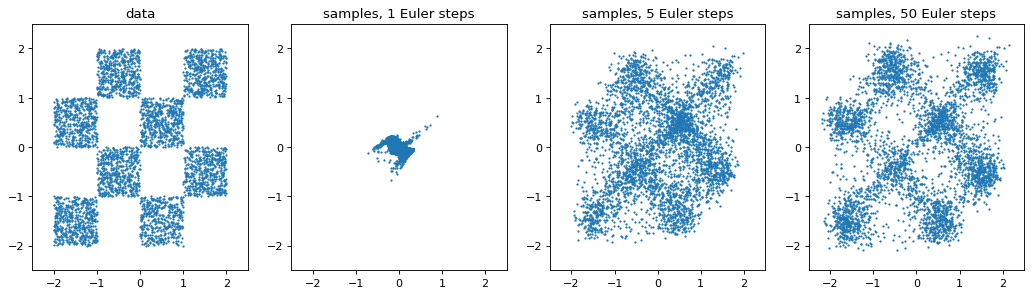

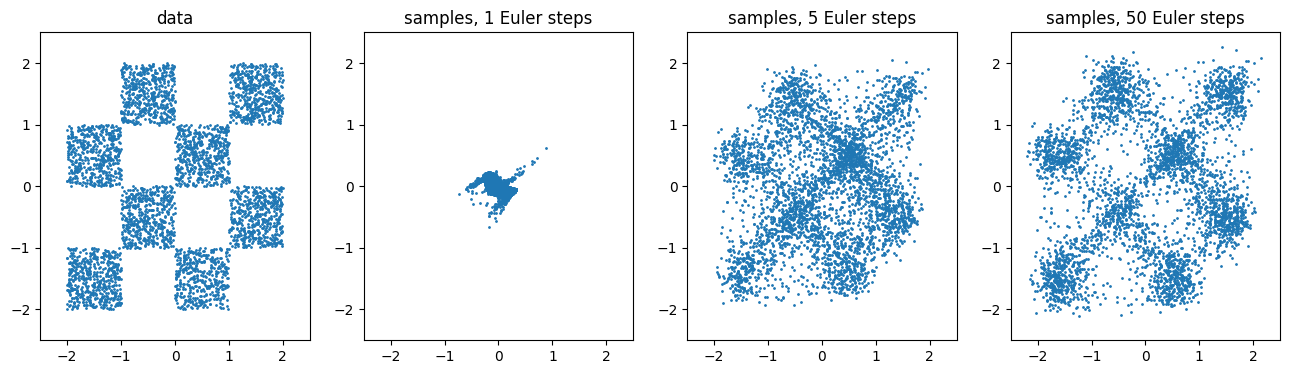

In [2]:
%run ../scripts/toy_2d.py
from IPython.display import Image

Image("toy_2d.png")

## Step 2 — images as tokens, and the DiT

CIFAR-10: 32×32×3 images, scaled to [-1, 1].

torch.Size([50000, 3, 32, 32]) torch.uint8
['airplane', 'frog', 'airplane', 'bird', 'horse', 'bird', 'automobile', 'bird']


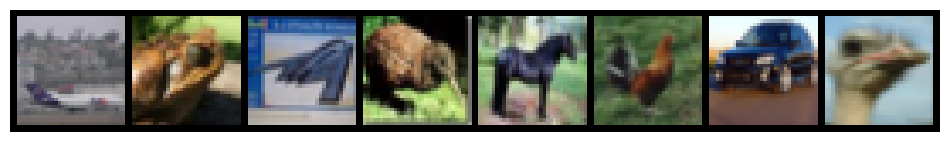

In [3]:
all_imgs, all_labels = load_cifar10("../data", "train")  # uint8 (50000, 3, 32, 32), downloads once
print(all_imgs.shape, all_imgs.dtype)
imgs, labels = to_model_range(all_imgs[:8]), all_labels[:8]  # float in [-1, 1]
show = to_image_range

grid = torchvision.utils.make_grid(show(imgs), nrow=8)
plt.figure(figsize=(12, 2))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
print([CLASSES[i] for i in labels])

### Patchify: (3, 32, 32) → 256 tokens × 12 numbers
Each token is a 2×2 patch with 3 colours. Rearranging only — `unpatchify` gives back the exact image.

In [4]:
tokens = patchify(imgs, p=2)
print("image  :", tuple(imgs.shape))
print("tokens :", tuple(tokens.shape), " (B, N, C)")
print("token 0:", tokens[0, 0])
print("roundtrip exact:", torch.equal(unpatchify(tokens, 2), imgs))

image  : (8, 3, 32, 32)
tokens : (8, 256, 12)  (B, N, C)
token 0: tensor([0.3961, 0.3804, 0.4824, 0.3961, 0.3804, 0.4824, 0.4118, 0.3961, 0.4980,
        0.4039, 0.3882, 0.4902])
roundtrip exact: True


### Noising per token
Same `add_noise`, two choices of `tau`:
* vanilla flow matching: every token gets the same `t`
* preview of Self-Flow: ~25% of tokens get a different noise level `s`

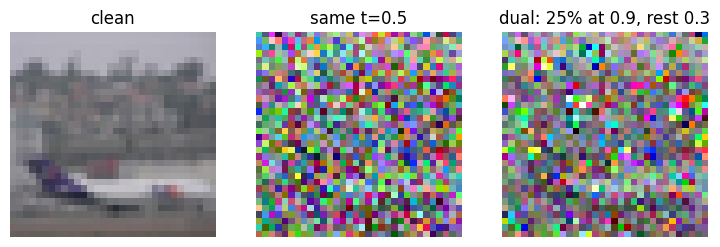

In [5]:
x0 = tokens[:1]
x1 = torch.randn_like(x0)
B, N, _ = x0.shape

tau_same = torch.full((B, N), 0.5)
mask = torch.rand(B, N) < 0.25
tau_dual = torch.where(mask, 0.9, 0.3)  # masked tokens much noisier (s=0.9), rest cleaner (t=0.3)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (title, im) in zip(
    ax,
    [
        ("clean", imgs[:1]),
        ("same t=0.5", unpatchify(add_noise(x0, x1, tau_same), 2)),
        ("dual: 25% at 0.9, rest 0.3", unpatchify(add_noise(x0, x1, tau_dual), 2)),
    ],
):
    a.imshow(show(im[0]).permute(1, 2, 0))
    a.set_title(title)
    a.axis("off")

### The DiT
tokens `(B,256,12)` → Linear → `(B,256,384)` → 12 transformer blocks → Linear → velocity `(B,256,12)`.
Each block is conditioned on its token's timestep + the class label via adaLN.

In [6]:
model = DiT(DiTConfig()).to(device)
print("params: %.1fM" % (sum(p.numel() for p in model.parameters()) / 1e6))

x = tokens.to(device)
tau = torch.rand(x.shape[:2], device=device)
v, feats = model.forward_features(x, tau, labels.to(device))
print("velocity:", tuple(v.shape), "| hidden states:", len(feats), "x", tuple(feats[0].shape))
print("output at init is zero (adaLN-Zero):", v.abs().max().item())

params: 32.6M
velocity: (8, 256, 12) | hidden states: 12 x (8, 256, 384)
output at init is zero (adaLN-Zero): 0.0


### Sanity check: can it learn? Overfit 256 images for a few hundred steps.
Real training (all of CIFAR, 4 GPUs) comes in Step 3. Here we just check the loss goes down and samples start looking like images.

Text(0, 0.5, 'flow loss')

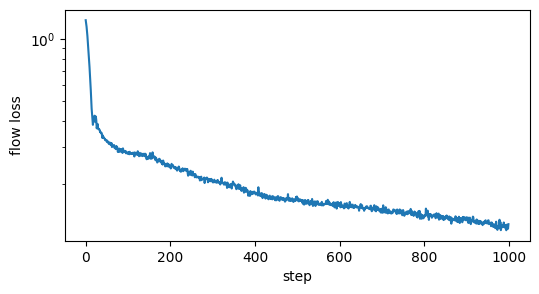

In [7]:
idx = torch.randperm(len(all_imgs))[:256]
batch_imgs, batch_y = to_model_range(all_imgs[idx]), all_labels[idx]
x0, y = patchify(batch_imgs, 2).to(device), batch_y.to(device)

model = DiT(DiTConfig()).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
losses = []
for step in range(1000):
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
        loss = flow_loss(model, x0, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())
plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("flow loss")

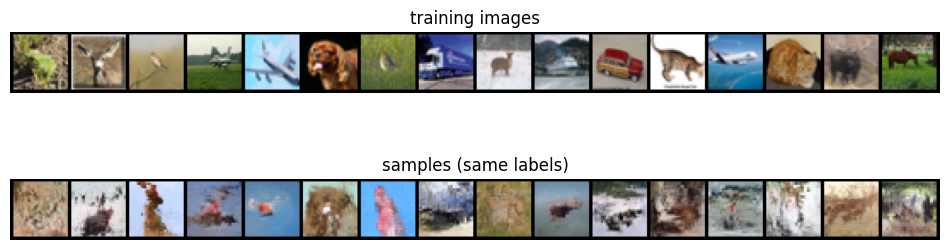

In [8]:
model.eval()
with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
    out = euler_sample(model, torch.randn(16, 256, 12, device=device), y[:16], steps=50)
samples = unpatchify(out.float(), 2).cpu()
fig, ax = plt.subplots(2, 1, figsize=(12, 3.5))
ax[0].imshow(torchvision.utils.make_grid(show(batch_imgs[:16]), nrow=16).permute(1, 2, 0))
ax[0].set_title("training images")
ax[1].imshow(torchvision.utils.make_grid(show(samples), nrow=16).permute(1, 2, 0))
ax[1].set_title("samples (same labels)")
for a in ax:
    a.axis("off")